In [ ]:
pip install -q docling

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.3/70.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 568.8/568.8 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.8/257.8 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.0/94.0 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 78.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 67.5 MB/s eta 0:00:00
   ━━

In [ ]:
from docling.document_converter import DocumentConverter
source = "/content/mrag-research-paper"
converter = DocumentConverter()
doc = converter.convert(source).document

[INFO] 2026-06-20 16:04:14,005 [RapidOCR] base.py:22: Using engine_name: torch
[INFO] 2026-06-20 16:04:14,013 [RapidOCR] device_config.py:57: Using CPU device
[INFO] 2026-06-20 16:04:14,018 [RapidOCR] download_file.py:68: Initiating download: https://www.modelscope.cn/models/RapidAI/RapidOCR/resolve/v3.8.0/torch/PP-OCRv4/det/ch_PP-OCRv4_det_mobile.pth
[INFO] 2026-06-20 16:04:14,958 [RapidOCR] download_file.py:82: Download size: 13.83MB
[INFO] 2026-06-20 16:04:15,690 [RapidOCR] download_file.py:95: Successfully saved to: /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_PP-OCRv4_det_mobile.pth
[INFO] 2026-06-20 16:04:15,693 [RapidOCR] main.py:50: Using /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_PP-OCRv4_det_mobile.pth
[INFO] 2026-06-20 16:04:16,023 [RapidOCR] base.py:22: Using engine_name: torch
[INFO] 2026-06-20 16:04:16,024 [RapidOCR] device_config.py:57: Using CPU device
[INFO] 2026-06-20 16:04:16,027 [RapidOCR] download_file.py:68: Initiating download: https

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

In [ ]:
import json
import hashlib
from pathlib import Path

from docling_core.transforms.chunker import HierarchicalChunker

# Create output directory
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Chunk document
chunker = HierarchicalChunker()
chunks = [chunk.text for chunk in chunker.chunk(doc)]

# Create JSON structure
chunk_json = {}

for chunk in chunks:
    chunk_hash = hashlib.sha256(
        chunk.encode("utf-8")
    ).hexdigest()

    chunk_json[chunk_hash] = chunk

# Save JSON
json_path = output_dir / "chunks.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        chunk_json,
        f,
        ensure_ascii=False,
        indent=2
    )

print(f"Saved {len(chunks)} chunks to {json_path}")

Saved 123 chunks to output/chunks.json


In [ ]:
pip install -q PyMuPDF ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.6 MB/s eta 0:00:00


In [ ]:
import os
import json
import fitz
from PIL import Image
from ultralytics import YOLO

# ─── CONFIG ───────────────────────────────────────────────
INPUT_FILE    = "/content/mrag-research-paper"
OUTPUT_DIR    = "output/images"
JSON_FILE     = "output/image_text.json"
MODEL_PATH    = "/content/yolov8s-doclaynet.pt"
DPI           = 200
CONFIDENCE    = 0.5
VICINITY      = 50    # PDF units — how far "nearby" means
# ──────────────────────────────────────────────────────────

FIGURE_LABELS = {"picture", "figure"}

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs("output", exist_ok=True)

model = YOLO(MODEL_PATH)

doc   = fitz.open(INPUT_FILE)
zoom  = DPI / 72
mat   = fitz.Matrix(zoom, zoom)
total = 0

result_json = {}  # { image_path: nearby_text }

for page_num in range(len(doc)):
    page = doc[page_num]
    pix  = page.get_pixmap(matrix=mat)
    page_image = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)

    results = model(page_image, conf=CONFIDENCE)[0]

    fig_count = 0
    for box, cls, conf in zip(results.boxes.xyxy, results.boxes.cls, results.boxes.conf):
        label = model.names[int(cls)].lower()
        if label not in FIGURE_LABELS:
            continue

        # ── Save image ──────────────────────────────────────
        x1, y1, x2, y2 = [int(c) for c in box]
        cropped  = page_image.crop((x1, y1, x2, y2))
        filename = f"page{page_num + 1}_figure{fig_count + 1}.png"
        img_path = os.path.join(OUTPUT_DIR, filename)
        cropped.save(img_path)

        # ── Get nearby text ──────────────────────────────────
        # Convert pixel bbox back to PDF units for text search
        pdf_x1 = x1 / zoom
        pdf_y1 = y1 / zoom
        pdf_x2 = x2 / zoom
        pdf_y2 = y2 / zoom

        # Expand the box by VICINITY to capture surrounding text
        search_rect = fitz.Rect(
            pdf_x1 - VICINITY,
            pdf_y1 - VICINITY,
            pdf_x2 + VICINITY,
            pdf_y2 + VICINITY
        )

        # Extract text only within that expanded region
        nearby_text = page.get_text("text", clip=search_rect).strip()

        # ── Store in JSON ────────────────────────────────────
        result_json[img_path] = nearby_text

        print(f"  Saved : {filename}  (conf: {conf:.2f})")
        print(f"  Text  : {nearby_text[:80]}{'...' if len(nearby_text) > 80 else ''}")

        fig_count += 1
        total += 1

    print(f"Page {page_num + 1}: {fig_count} figure(s) found\n")

doc.close()

# ── Write JSON ───────────────────────────────────────────
with open(JSON_FILE, "w", encoding="utf-8") as f:
    json.dump(result_json, f, indent=4, ensure_ascii=False)

print(f"[✓] Done! {total} images saved to : {OUTPUT_DIR}/")
print(f"[✓] JSON saved to                 : {JSON_FILE}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

0: 1024x800 1 Page-footer, 5 Section-headers, 15 Texts, 1 Title, 4687.8ms
Speed: 43.8ms preprocess, 4687.8ms inference, 22.2ms postprocess per image at shape (1, 3, 1024, 800)
Page 1: 0 figure(s) found


0: 1024x800 1 List-item, 1 Page-footer, 1 Page-header, 1 Picture, 8 Texts, 2575.8ms
Speed: 47.4ms preprocess, 2575.8ms inference, 1.2ms postprocess per image at shape (1, 3, 1024, 800)
  Saved : page2_figure1.png  (conf: 0.94)
  Text  : MM ’25, October 27–31, 2025, Dublin, Ireland
Figure 1: Comparison of (𝑎) single-...
Page 2: 1 figure(s) found


0: 1024x800 1 Formula, 3 List-items, 1 Page-footer, 5 Section-headers, 10 Texts, 1325.4ms
Speed: 16.6ms preprocess, 1325.4ms inference,

In [ ]:
pip install -q groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 2.1 MB/s eta 0:00:00


In [ ]:
import os
import json
import hashlib
from groq import Groq

# ─── CONFIG ───────────────────────────────────────────────
INPUT_JSON  = "output/image_text.json"
OUTPUT_JSON = "output/image_descriptions.json"
client = Groq(api_key="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")
# ──────────────────────────────────────────────────────────

def image_to_base64_for_groq(image_path):
    import base64
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

def sha256_hash(image_path):
    with open(image_path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

def generate_description(image_base64, nearby_text):
    prompt = f"""
You are extracting information from a PDF.
Nearby text:
{nearby_text}
Task:
Generate a concise, information-dense description of the image.
Use nearby text only when relevant.
Return only the description.
"""
    completion = client.chat.completions.create(
        model="meta-llama/llama-4-scout-17b-16e-instruct",
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": f"data:image/jpeg;base64,{image_base64}"},
                    },
                ],
            }
        ],
        temperature=0.2,
        max_completion_tokens=300,
    )
    return completion.choices[0].message.content

# ─── MAIN ─────────────────────────────────────────────────
with open(INPUT_JSON, "r") as f:
    image_text = json.load(f)

output = {}

for img_path, nearby_text in image_text.items():
    if not os.path.exists(img_path):
        print(f"  Skipping (not found): {img_path}")
        continue

    print(f"Processing: {img_path}")

    b64         = image_to_base64_for_groq(img_path)   # only for API call
    sha         = sha256_hash(img_path)
    description = generate_description(b64, nearby_text)

    output[sha] = [img_path, description]              # path instead of base64
    print(f"  Hash : {sha[:20]}...")
    print(f"  Desc : {description[:80]}...")

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(output, f, indent=4, ensure_ascii=False)

print(f"\n[✓] Done! Saved to: {OUTPUT_JSON}")

Processing: output/images/page2_figure1.png
  Hash : 8ceaf231aa453c62f7c7...
  Desc : The image presents a comparison between two types of RAG (Retrieval-Augmented Ge...
Processing: output/images/page4_figure1.png
  Hash : ff24611adb52c958332e...
  Desc : The image illustrates a multi-agent, multi-modal framework called HM-RAG, which ...
Processing: output/images/page8_figure1.png
  Hash : c75cdee6206330427c4e...
  Desc : A map of the eastern United States with one highlighted colony in dark green, lo...

[✓] Done! Saved to: output/image_descriptions.json


In [ ]:
import json
from pathlib import Path
from sentence_transformers import SentenceTransformer, util

# -------- Paths --------
output_dir = Path("output")
chunks_path = output_dir / "chunks.json"
images_path = output_dir / "image_descriptions.json"
merged_path = output_dir / "merged_chunks_images.json"

# -------- Load JSON files --------
with open(chunks_path, "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

with open(images_path, "r", encoding="utf-8") as f:
    images_json = json.load(f)

# -------- Load CLIP text embedding model --------
model = SentenceTransformer("clip-ViT-B-32")

# -------- Prepare data --------
chunk_ids   = list(chunks_json.keys())
chunk_texts = list(chunks_json.values())

image_ids         = list(images_json.keys())
image_descriptions = [images_json[img_id][1] for img_id in image_ids]

# -------- Create embeddings --------
chunk_embeddings = model.encode(chunk_texts, convert_to_tensor=True)
image_embeddings = model.encode(image_descriptions, convert_to_tensor=True)

# -------- Similarity threshold --------
SIMILARITY_THRESHOLD = 0.8   # CLIP scores are lower than MiniLM — adjust accordingly

merged_json = {}

# -------- Compare every chunk with every image description --------
for i, chunk_id in enumerate(chunk_ids):
    for j, image_id in enumerate(image_ids):

        similarity = util.cos_sim(
            chunk_embeddings[i],
            image_embeddings[j]
        ).item()

        if similarity >= SIMILARITY_THRESHOLD:
            key = f"({chunk_id}, {image_id})"
            merged_json[key] = {
                "chunk_id"  : chunk_id,
                "image_id"  : image_id,
                "similarity": round(similarity, 4),
                "content"   : chunks_json[chunk_id] + "\n\n" + image_descriptions[j]
            }

# -------- Save new JSON --------
with open(merged_path, "w", encoding="utf-8") as f:
    json.dump(merged_json, f, ensure_ascii=False, indent=2)

print(f"Saved {len(merged_json)} merged records to {merged_path}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Saved 28 merged records to output/merged_chunks_images.json


In [ ]:
import json

# -------- Paths --------
output_dir = Path("output")
chunks_path = output_dir / "chunks.json"
merged_path = output_dir / "merged_chunks_images.json"

# -------- Load JSON files --------
with open(chunks_path, "r", encoding="utf-8") as f:
    text_chunks = json.load(f)

with open(merged_path, "r", encoding="utf-8") as f:
    merged_chunks = json.load(f)

chunks_database = {}

for chunk_id, chunk_text in text_chunks.items():
    chunks_database[chunk_id] = chunk_text

for merged_id, merged_data in merged_chunks.items():
    key = f"({merged_data['chunk_id']},{merged_data['image_id']})"
    value = f"{merged_data['content']}"
    chunks_database[key] = value

chunksDatabase = output_dir / "chunks_database.json"

with open(chunksDatabase, "w", encoding="utf-8") as f:
    json.dump(chunks_database, f, ensure_ascii=False, indent=2)

print(f"Saved {len(chunks_database)} records to {chunksDatabase}")

Saved 138 records to output/chunks_database.json


In [ ]:
pip install -q chromadb sentence-transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 62.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.8/71.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.9/170.9 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.7/203.7 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 4.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the s

In [ ]:
import json
from pathlib import Path

import chromadb
from sentence_transformers import SentenceTransformer


# -------- Paths --------
output_dir = Path("output")

chunks_path = output_dir / "chunks.json"
merged_path = output_dir / "merged_chunks_images.json"

chroma_path = "chroma_db"


# -------- Load JSON files --------
with open(chunks_path, "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

with open(merged_path, "r", encoding="utf-8") as f:
    merged_json = json.load(f)


# -------- Embedding model --------
model = SentenceTransformer("all-MiniLM-L6-v2")


# -------- ChromaDB setup --------
client = chromadb.PersistentClient(path=chroma_path)

collection = client.get_or_create_collection(
    name="pdf_chunks"
)


# -------- Prepare records --------
ids = []
documents = []
metadatas = []

# 1. Add normal chunks
for chunk_id, chunk_text in chunks_json.items():
    ids.append(chunk_id)
    documents.append(chunk_text)
    metadatas.append({
        "type": "text_chunk",
        "chunk_id": chunk_id
    })

# 2. Add merged chunk + image descriptions
for merged_id, merged_data in merged_json.items():

    # If your merged JSON value is a dict
    if isinstance(merged_data, dict):
        text = merged_data["content"]
        chunk_id = merged_data.get("chunk_id")
        image_id = merged_data.get("image_id")
        similarity = merged_data.get("similarity")

    # If your merged JSON value is only plain text
    else:
        text = merged_data
        chunk_id = None
        image_id = None
        similarity = None

    ids.append(merged_id)
    documents.append(text)
    metadatas.append({
        "type": "merged_chunk_image",
        "chunk_id": chunk_id or "",
        "image_id": image_id or "",
        "similarity": similarity or 0
    })


# -------- Create embeddings --------
embeddings = model.encode(
    documents,
    convert_to_numpy=True
).tolist()


# -------- Save to ChromaDB --------
collection.add(
    ids=ids,
    documents=documents,
    embeddings=embeddings,
    metadatas=metadatas
)

print(f"Saved {len(ids)} records to ChromaDB")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Saved 138 records to ChromaDB


In [ ]:
data = collection.get()

import pandas as pd

df = pd.DataFrame({
    "id": data["ids"],
    "document": data["documents"],
    "metadata": data["metadatas"]
})

print(df.head())

                                                  id  \
0  822893157f3a7d2c07dfa32e88f107da0d131a150c9312...   
1  860248eedae7eb6b9e08279a945d62270cf857c0cb5cc8...   
2  e3680f4c22d0e3d307d9a45f5ff97f49ac74e6076b24f7...   
3  1dc9b749bd852d5c39642384c0c0ab63f02bf567130261...   
4  319c483408fb30da45f64ae2592f5193b31c3a01548215...   

                                            document  \
0  pliu061@connect.hkust-gz.edu.cn The Hong Kong ...   
1  liu_junming6917@tongji.edu.cn Tongji Universit...   
2  While Retrieval-Augmented Generation (RAG) aug...   
3  ∗ This work was completed during Pei Liu's int...   
4                            † Corresponding author.   

                                            metadata  
0  {'chunk_id': '822893157f3a7d2c07dfa32e88f107da...  
1  {'type': 'text_chunk', 'chunk_id': '860248eeda...  
2  {'chunk_id': 'e3680f4c22d0e3d307d9a45f5ff97f49...  
3  {'type': 'text_chunk', 'chunk_id': '1dc9b749bd...  
4  {'chunk_id': '319c483408fb30da45f64ae2592f5193..

In [ ]:
from sentence_transformers import SentenceTransformer
import chromadb

# Load embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Load ChromaDB
client = chromadb.PersistentClient(path="chroma_db")

collection = client.get_collection("pdf_chunks")

# Query
query = "Explain me Overview of HM-RAG. A multi-agent multi-modal framework."

# Encode query
query_embedding = model.encode(
    query,
    convert_to_numpy=True
).tolist()

# Retrieve top 10 most similar documents
results = collection.query(
    query_embeddings=[query_embedding],
    n_results=20
)

# Print results
for rank, (doc_id, doc, distance) in enumerate(
    zip(
        results["ids"][0],
        results["documents"][0],
        results["distances"][0]
    ),
    start=1
):
    print(f"\nRank: {rank}")
    print(f"ID: {doc_id}")
    print(f"Distance: {distance}")
    print(f"Document: {doc[:500]}...")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Rank: 1
ID: 78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2
Distance: 0.4897738993167877
Document: Figure 2: Overview of HM-RAG. A multi-agent multi-modal framework operates in three stages: First, the Decomposition Agent uses an LLM to rewrite and decompose the question into several sub-queries. Second, the Multi-source Retrieval Agent retrieves the top-k relevant documents from vector-, graph- and web-based sources as needed. Finally, the Decision Agent provides a voting mechanism and refinement process to generate the final answer....

Rank: 2
ID: 98c5f5f6ddaed13a4f6efee902a20ac96ab3f829cbf19824684ac6dd5bf40a6b
Distance: 0.5709487199783325
Document: (b) Multi-agent Multimodal RAG...

Rank: 3
ID: 4b7d3384c56029e0b190467d4d394fef8e0b43b043d91a7268514bf177fc913b
Distance: 0.5754169821739197
Document: (a) Single-agent Single-modal RAG...

Rank: 4
ID: (d5021be4b51ed32fbffa5cac926b991c13fa1cd5e352392ea3aa38fe7996504b, ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc

In [ ]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder(
    "BAAI/bge-reranker-base"
)

pairs = [
    [query, doc]
    for doc in results["documents"][0]
]

scores = reranker.predict(pairs)

reranked_results = sorted(
    zip(
        results["ids"][0],
        results["documents"][0],
        scores
    ),
    key=lambda x: x[2],
    reverse=True
)

top_3 = reranked_results[:5]

for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
    print(f"\nRank: {rank}")
    print(f"ID: {doc_id}")
    print(f"Score: {score:.4f}")
    print(f"Document: {doc[:500]}...")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Rank: 1
ID: 78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2
Score: 0.9994
Document: Figure 2: Overview of HM-RAG. A multi-agent multi-modal framework operates in three stages: First, the Decomposition Agent uses an LLM to rewrite and decompose the question into several sub-queries. Second, the Multi-source Retrieval Agent retrieves the top-k relevant documents from vector-, graph- and web-based sources as needed. Finally, the Decision Agent provides a voting mechanism and refinement process to generate the final answer....

Rank: 2
ID: (78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2, ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc1eaa8982f3f)
Score: 0.9993
Document: Figure 2: Overview of HM-RAG. A multi-agent multi-modal framework operates in three stages: First, the Decomposition Agent uses an LLM to rewrite and decompose the question into several sub-queries. Second, the Multi-source Retrieval Agent retrieves the top-k relevant documents from

In [ ]:
import json
from pathlib import Path

# --------------------------
# Load JSON files
# --------------------------
output_dir = Path("output")

with open(output_dir / "chunks.json", "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

with open(output_dir / "image_descriptions.json", "r", encoding="utf-8") as f:
    images_json = json.load(f)

retrieved_images = {}

# --------------------------
# Print ranked results
# --------------------------
print("\nRANKED RESULTS")
print("=" * 100)

for rank, (doc_id, doc_content, score) in enumerate(top_3, start=1):
    print(f"\nRank: {rank}")
    print(f"ID: {doc_id}")
    print(f"Score: {score:.4f}")
    print(f"Document: {doc_content[:500]}...")

    # Check if it's a merged ID and extract individual IDs
    if doc_id.startswith("(") and doc_id.endswith(")"):
        ids_str = doc_id[1:-1]  # remove '(' and ')'
        try:
            chunk_id, image_id = [x.strip() for x in ids_str.split(",", maxsplit=1)]
            if image_id in images_json:
                image_data = images_json[image_id]
                print("  --- Image Information ---")
                print(f"  Image Path: {image_data[0]}")
                print(f"  Image Description: {image_data[1][:80]}...")
                retrieved_images[image_id] = image_data
        except ValueError:
            print(f"  Could not parse merged ID: {doc_id}")



RANKED RESULTS

Rank: 1
ID: 78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2
Score: 0.9994
Document: Figure 2: Overview of HM-RAG. A multi-agent multi-modal framework operates in three stages: First, the Decomposition Agent uses an LLM to rewrite and decompose the question into several sub-queries. Second, the Multi-source Retrieval Agent retrieves the top-k relevant documents from vector-, graph- and web-based sources as needed. Finally, the Decision Agent provides a voting mechanism and refinement process to generate the final answer....

Rank: 2
ID: (78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2, ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc1eaa8982f3f)
Score: 0.9993
Document: Figure 2: Overview of HM-RAG. A multi-agent multi-modal framework operates in three stages: First, the Decomposition Agent uses an LLM to rewrite and decompose the question into several sub-queries. Second, the Multi-source Retrieval Agent retrieves the top-k relevan

In [ ]:
pip install -q langchain-groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.7 MB/s eta 0:00:00


In [ ]:
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
import os
import base64

llm = ChatGroq(
    model="meta-llama/llama-4-scout-17b-16e-instruct",
    api_key="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",
    temperature=0.2,
    max_tokens=700
)

# --------------------------
# Prepare text context and collect images for LLM
# --------------------------
text_context = ""
images_for_llm = [] # List to store image info for content list

for rank, (doc_id, doc_content, score) in enumerate(top_3, start=1):
    text_context += f"\n\n--- Document Rank {rank} (Score: {score:.4f}) ---\n"
    text_context += f"ID: {doc_id}\n"
    text_context += f"Content: {doc_content}\n"

    # Check if it's a merged ID and extract individual IDs to find associated image
    if doc_id.startswith("(") and doc_id.endswith(")"):
        ids_str = doc_id[1:-1]
        try:
            chunk_id, image_id = [x.strip() for x in ids_str.split(",", maxsplit=1)]
            if image_id in images_json:
                image_data = images_json[image_id] # [image_path, description]
                images_for_llm.append({
                    "rank": rank,
                    "image_path": image_data[0],
                    "description": image_data[1]
                })
                # Add image description to text_context as well
                text_context += f"Associated Image (Image ID: {image_id}): {image_data[1]}\n"
        except ValueError:
            # This case should ideally not happen if doc_id is well-formed
            pass
    else:
        text_context += "Type: Text Chunk\n"

# --------------------------
# Prepare multimodal message
# --------------------------
content = [
    {
        "type": "text",
        "text": f"""
You are answering a user query using retrieved PDF text chunks and related images.

User query:
{query}

Retrieved documents (ranked by relevance, including associated images):
{text_context}

Instructions:
- Answer only from the provided context.
- Use images only when relevant. Refer to them by their associated rank (e.g., "Image from Rank 1").
- If the answer is not present, say that the provided context is insufficient.
- Be clear and concise.
"""
    }
]

def path_to_base64(image_path):
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

# Add images to the content list, explicitly linking them to their rank
# Limit to top 5 images, as per original code's [:5] slicing
for img_info in images_for_llm[:5]:
    image_base64 = path_to_base64(img_info["image_path"])
    content.append(
        {
            "type": "image_url",
            "image_url": {
                "url": f"data:image/jpeg;base64,{image_base64}"
            }
        }
    )
    content.append(
        {
            "type": "text",
            "text": f"This image is associated with Document Rank {img_info['rank']}. Description: {img_info['description']}"
        }
    )

# --------------------------
# Invoke Vision LLM
# --------------------------
response = llm.invoke([
    HumanMessage(content=content)
])
answer = response.content
print(response.content)


The HM-RAG (Hierarchical Multi-Agent Retrieval-Augmented Generation) framework is a multi-agent, multi-modal framework designed to answer complex questions by operating in three stages. 

## Overview of HM-RAG

### Components of HM-RAG

1. **Decomposition Agent**: This agent uses a Large Language Model (LLM) to rewrite and decompose the input question into several sub-queries. This process enables the framework to handle complex, multi-intent user queries that require joint reasoning across multiple data sources.

2. **Multi-source Retrieval Agent**: This agent retrieves the top-k relevant documents from various sources, including:
   - Vector-based sources
   - Graph-based sources
   - Web-based sources

   as needed. The agent employs different retrieval methods, such as:
   - Vector-based naive retrieval
   - Graph-based dual-level retrieval

3. **Decision Agent**: This agent provides a voting mechanism and a refinement process to generate the final answer. The Decision Agent refine

In [ ]:
pip install -q networkx sentence-transformers

In [ ]:
import networkx as nx
from sentence_transformers import SentenceTransformer, util
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import sent_tokenize

model = SentenceTransformer("all-MiniLM-L6-v2")

# sentences = answer.split(". ")
sentences = sent_tokenize(answer)
image_ids = list(retrieved_images.keys())
image_descriptions = [
    retrieved_images[img_id][1]
    for img_id in image_ids
]

sentence_embeddings = model.encode(sentences, convert_to_tensor=True)
image_embeddings = model.encode(image_descriptions, convert_to_tensor=True)

G = nx.Graph()

for i, sentence in enumerate(sentences):
    for j, image_id in enumerate(image_ids):
        similarity = util.cos_sim(
            sentence_embeddings[i],
            image_embeddings[j]
        ).item()

        if similarity > 0.2:
            G.add_edge(
                f"s_{i}",
                f"img_{j}",
                weight=similarity
            )

matching = nx.algorithms.matching.max_weight_matching(
    G,
    maxcardinality=False
)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [ ]:
sentence_to_image = {}

for a, b in matching:
    if a.startswith("s_"):
        sentence_id = int(a.split("_")[1])
        image_id = image_ids[int(b.split("_")[1])]
    else:
        sentence_id = int(b.split("_")[1])
        image_id = image_ids[int(a.split("_")[1])]

    sentence_to_image[sentence_id] = image_id

In [ ]:
for i, sentence in enumerate(sentences):
    print(sentence)

    if i in sentence_to_image:
        img_id = sentence_to_image[i]
        print(f"\n[Insert image: {img_id}]\n")

The HM-RAG (Hierarchical Multi-Agent Retrieval-Augmented Generation) framework is a multi-agent, multi-modal framework designed to answer complex questions by operating in three stages.

[Insert image: ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc1eaa8982f3f]

## Overview of HM-RAG

### Components of HM-RAG

1.
**Decomposition Agent**: This agent uses a Large Language Model (LLM) to rewrite and decompose the input question into several sub-queries.
This process enables the framework to handle complex, multi-intent user queries that require joint reasoning across multiple data sources.
2.
**Multi-source Retrieval Agent**: This agent retrieves the top-k relevant documents from various sources, including:
   - Vector-based sources
   - Graph-based sources
   - Web-based sources

   as needed.
The agent employs different retrieval methods, such as:
   - Vector-based naive retrieval
   - Graph-based dual-level retrieval

3.
**Decision Agent**: This agent provides a voting mechanism 

**EVALUATION - RETRIEVAL**

Dataset Creation

In [ ]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain_groq import ChatGroq


class ContactInfo(BaseModel):
    question: str = Field(description="Question")
    answer: str = Field(description="Answer")


dataset = {}


llm = ChatGroq(model="llama-3.3-70b-versatile",
    api_key="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",
)

agent = create_agent(
    model=llm,
    response_format=ContactInfo,
)

def generateQuestionAnswer(chunk_id, chunk_text):
  result = agent.invoke(
      {
          "messages" : [
              {
                  "role" : "user",
                  "content" : f"Generate a meaningful question and its very detailedanswer from the text chunk {chunk_text} if possible. If not possible do not generate anything"
              }
          ]
      }
  )
  structured = result["structured_response"]
  dataset[chunk_id] = {
      "question": structured.question,
      "answer": structured.answer
  }

counter = 50
for chunk_id, chunk_text in chunks_database.items():
    if counter >= 90:
      generateQuestionAnswer(chunk_id, chunk_text)
    counter += 1
    if counter == 100:
      break

jsonData = json.dumps(dataset, indent=4)
print(jsonData)

{
    "7ac603ec526cf64e4171e72af06ef7d12c2e3c9eb4cf57c96990cf33f243add1": {
        "question": "What are the limitations of text-only RAG systems and how have they evolved to address these limitations?",
        "answer": "Text-only RAG systems have limitations in handling visually rich documents, prompting the development of image-based RAG approaches that aim to retrieve visual content for Large Vision-Language Models (VLMs). However, these methods faced challenges in effectively integrating text and image modalities. To address these limitations, RAG systems have evolved to enhance their multimodal reasoning capabilities by integrating Large Language Models (LLMs) with external textual knowledge and developing image-based RAG approaches that can retrieve visual content and integrate it with text modalities."
    },
    "a7930f04ac6f7105912c5810c5a664402056b4f75949e799ad8bcc33dbfe3512": {
        "question": "What are the limitations of current Retrieval-Augmented Generation (RAG) s

In [ ]:
import json

with open("dataset.json", "w", encoding="utf-8") as f:
    json.dump(dataset, f, indent=4, ensure_ascii=False)

In [ ]:
from sentence_transformers import SentenceTransformer
import chromadb

# Load embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Load ChromaDB
client = chromadb.PersistentClient(path="chroma_db")

collection = client.get_collection("pdf_chunks")

# Query
query = "What is HM-RAG and how does it tackle complex challenges in RAG systems?"

# Encode query
query_embedding = model.encode(
    query,
    convert_to_numpy=True
).tolist()

# Retrieve top 10 most similar documents
results = collection.query(
    query_embeddings=[query_embedding],
    n_results=20
)

# Print results
for rank, (doc_id, doc, distance) in enumerate(
    zip(
        results["ids"][0],
        results["documents"][0],
        results["distances"][0]
    ),
    start=1
):
    print(f"\nRank: {rank}")
    print(f"ID: {doc_id}")
    print(f"Distance: {distance}")
    print(f"Document: {doc[:500]}...")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Rank: 1
ID: 9a42d1349e7d6c512e3f23fb1e0929ab5d70bc167c36f73214805fa3acbb036c
Distance: 0.7577943801879883
Document: In this section, we conduct a systematic evaluation of HM-RAG against state-of-the-art zero-shot LLMs, VLMs, and RAG-enhanced approaches across multiple benchmarks. The results are presented in Table 1 and Table 2, which demonstrate the consistent superiority of HM-RAG over all comparative methods ....

Rank: 2
ID: e998a5d5831defce16a53a8559dbfb0315386fa08f92f29a066b19829b4bcf06
Distance: 0.9013528823852539
Document: Figure 3: Case Study: Comparison Between HM-RAG and the Baseline Methods (Vector-based, Graph-based, and Web-based Retrieval Agent)....

Rank: 3
ID: b21e92b9c65e86b167b631dea0944b5ed52404ce887ebfc0133625a7206eff16
Distance: 1.0012099742889404
Document: Table 3: Performance comparison across different variants of HM-RAGontheScienceQADataset. Components include: VA (Vector-based Retrieval Agent), GA (Graph-based Retrieval Agent), WA (Web-based Retrieval Agent)

In [ ]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder(
    "BAAI/bge-reranker-base"
)

pairs = [
    [query, doc]
    for doc in results["documents"][0]
]

scores = reranker.predict(pairs)

reranked_results = sorted(
    zip(
        results["ids"][0],
        results["documents"][0],
        scores
    ),
    key=lambda x: x[2],
    reverse=True
)

top_3 = reranked_results[:5]

for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
    print(f"\nRank: {rank}")
    print(f"ID: {doc_id}")
    print(f"Score: {score:.4f}")
    print(f"Document: {doc[:500]}...")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Rank: 1
ID: bc2862ae5d6a3c4f9a80dce7d35d6ecd086d64ad8ce23857cd558545fecd5ebd
Score: 0.9974
Document: We introduce HM-RAG, a novel framework tackling complex challenges in RAG systems. As depicted in Figure 2, HM-RAG features an innovative multi-agent, multimodal architecture with specialized agents for information extraction and multi-source retrieval. Given a natural language question 𝑞 and a reference document D , RAG retrieves semantically relevant content from D , integrating it with generative language models to produce answers strictly grounded in D . This approach advances multimodal que...

Rank: 2
ID: (bc2862ae5d6a3c4f9a80dce7d35d6ecd086d64ad8ce23857cd558545fecd5ebd, ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc1eaa8982f3f)
Score: 0.9973
Document: We introduce HM-RAG, a novel framework tackling complex challenges in RAG systems. As depicted in Figure 2, HM-RAG features an innovative multi-agent, multimodal architecture with specialized agents for information extractio

In [ ]:
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
import os
import base64

llm = ChatGroq(
    model="meta-llama/llama-4-scout-17b-16e-instruct",
    api_key="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",
    temperature=0.2,
    max_tokens=700
)

# --------------------------
# Prepare text context and collect images for LLM
# --------------------------
text_context = ""
images_for_llm = [] # List to store image info for content list

for rank, (doc_id, doc_content, score) in enumerate(top_3, start=1):
    text_context += f"\n\n--- Document Rank {rank} (Score: {score:.4f}) ---\n"
    text_context += f"ID: {doc_id}\n"
    text_context += f"Content: {doc_content}\n"

    # Check if it's a merged ID and extract individual IDs to find associated image
    if doc_id.startswith("(") and doc_id.endswith(")"):
        ids_str = doc_id[1:-1]
        try:
            chunk_id, image_id = [x.strip() for x in ids_str.split(",", maxsplit=1)]
            if image_id in images_json:
                image_data = images_json[image_id] # [image_path, description]
                images_for_llm.append({
                    "rank": rank,
                    "image_path": image_data[0],
                    "description": image_data[1]
                })
                # Add image description to text_context as well
                text_context += f"Associated Image (Image ID: {image_id}): {image_data[1]}\n"
        except ValueError:
            # This case should ideally not happen if doc_id is well-formed
            pass
    else:
        text_context += "Type: Text Chunk\n"

# --------------------------
# Prepare multimodal message
# --------------------------
content = [
    {
        "type": "text",
        "text": f"""
You are answering a user query using retrieved PDF text chunks and related images.

User query:
{query}

Retrieved documents (ranked by relevance, including associated images):
{text_context}

Instructions:
- Answer only from the provided context.
- Use images only when relevant. Refer to them by their associated rank (e.g., "Image from Rank 1").
- If the answer is not present, say that the provided context is insufficient.
- Be clear and concise.
"""
    }
]

def path_to_base64(image_path):
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

# Add images to the content list, explicitly linking them to their rank
# Limit to top 5 images, as per original code's [:5] slicing
for img_info in images_for_llm[:5]:
    image_base64 = path_to_base64(img_info["image_path"])
    content.append(
        {
            "type": "image_url",
            "image_url": {
                "url": f"data:image/jpeg;base64,{image_base64}"
            }
        }
    )
    content.append(
        {
            "type": "text",
            "text": f"This image is associated with Document Rank {img_info['rank']}. Description: {img_info['description']}"
        }
    )

# --------------------------
# Invoke Vision LLM
# --------------------------
response = llm.invoke([
    HumanMessage(content=content)
])
answer = response.content
print(response.content)


## HM-RAG: A Novel Framework for Tackling Complex Challenges in RAG Systems

HM-RAG stands for Hierarchical Multi-Agent Multimodal Retrieval Augmented Generation. It is a novel framework designed to tackle complex challenges in RAG (Retrieval-Augmented Generation) systems.

### Key Features of HM-RAG

*   **Multi-Agent Architecture**: HM-RAG features a multi-agent architecture with specialized agents for information extraction and multi-source retrieval.
*   **Multimodal Capabilities**: It operates on multimodal data, including text and images, advancing multimodal question answering and multi-agent RAG capabilities.

### Components of HM-RAG

The framework consists of three primary agents:

1.  **Decomposition Agent**: This agent uses a Large Language Model (LLM) to rewrite and decompose the question into several sub-queries.
2.  **Multi-Source Retrieval Agent**: This agent retrieves the top-k relevant documents from various sources, including vector-, graph-, and web-based sources.
3

In [ ]:
# Check if Top 5 chunks have the actual chunk
realChunkContent = None
realChunkId = None
realAnswer = None
query = query
flag_ChunkPresentOrNot = False
for key, value in dataset.items():
  if value['question'] == query:
     flag_ChunkPresentOrNot = True
     realAnswer = value['answer']
     realChunkContent = chunks_database[key]
     realChunkId = key
     break

print(realChunkContent)
print(realChunkId)
print(realAnswer)
print(query)

None
None
None
What is HM-RAG and how does it tackle complex challenges in RAG systems?


In [ ]:
# k = rankOfRealChunk = None
# N = 5
# if flag_ChunkPresentOrNot == True:
#   for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
#     if doc_id == realChunkId:
#       rankOfRealChunk = rank
#       break
#   print(f"Rank: {rank}")
#   realChunkEmbeddings = model.encode(realChunkContent, convert_to_tensor=True)
#   productOfDistanceVsWeight = 0
#   for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
#     if rank != rankOfRealChunk:
#       currentChunkEmbeddings = model.encode(doc, convert_to_tensor=True)
#       productOfDistanceVsWeight = productOfDistanceVsWeight + (util.cos_sim(realChunkEmbeddings, currentChunkEmbeddings) * (1/rank))
#   productOfDistanceVsWeight = float(productOfDistanceVsWeight[0][0])
#   errorPoint = (k/N)*[(1/(N-1) * productOfDistanceVsWeight)]
#   print(f"ErrorPoint: {errorPoint}")

# ===========================================================================================================================

# k = rankOfRealChunk = None
# N = 5

# if flag_ChunkPresentOrNot == True:
#     for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
#         if doc_id == realChunkId:
#             rankOfRealChunk = rank
#             k = rank
#             break

#     print(f"Rank of Real Chunk: {k}")

#     realChunkEmbeddings = model.encode(realChunkContent, convert_to_tensor=True)

#     weightedSum = 0
#     normalization = sum(1/i for i in range(1, N+1) if i != k)

#     for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
#         if rank != k:
#             currentChunkEmbeddings = model.encode(doc, convert_to_tensor=True)
#             sim = float(util.cos_sim(realChunkEmbeddings, currentChunkEmbeddings)[0][0])
#             weightedSum += sim * (1/rank)

#     errorPoint = (k/N) * (weightedSum / normalization)
#     print(f"ErrorPoint: {errorPoint}")

In [ ]:
# k = rankOfRealChunk = None
# N = 5
# if flag_ChunkPresentOrNot == False:
#   for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
#     if doc_id == realChunkId:
#       rankOfRealChunk = rank
#       break
#   print(f"Rank: {rank}")
#   realChunkEmbeddings = model.encode(realChunkContent, convert_to_tensor=True)
#   productOfDistanceVsWeight = 0
#   for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
#     currentChunkEmbeddings = model.encode(doc, convert_to_tensor=True)
#     productOfDistanceVsWeight = productOfDistanceVsWeight + (util.cos_sim(realChunkEmbeddings, currentChunkEmbeddings) * (1/rank))
#   productOfDistanceVsWeight = float(productOfDistanceVsWeight[0][0])
#   errorPoint = (1/(N-1) * productOfDistanceVsWeight)
#   print(f"ErrorPoint: {errorPoint}")

# ====================================================================================================

# k = rankOfRealChunk = None
# N = 5
# LAMBDA = 1.5

# if flag_ChunkPresentOrNot == False:

#     realChunkEmbeddings = model.encode(realChunkContent, convert_to_tensor=True)
#     queryEmbeddings = model.encode(query, convert_to_tensor=True)

#     weightedSum = 0
#     normalization = sum(1/i for i in range(1, N+1))

#     for rank, (doc_id, doc, score) in enumerate(top_3, start=1):
#         currentChunkEmbeddings = model.encode(doc, convert_to_tensor=True)
#         sim = float(util.cos_sim(realChunkEmbeddings, currentChunkEmbeddings)[0][0])
#         weightedSum += sim * (1/rank)

#     d_real = float(util.cos_sim(queryEmbeddings, realChunkEmbeddings)[0][0])

#     errorPoint = (weightedSum / normalization) + (LAMBDA * d_real)
#     print(f"ErrorPoint: {errorPoint}")


In [ ]:
# =============================================================================
# EVALUATION — RETRIEVAL (Full Dataset)
# Metrics: Hit@5, MRR, Mean Error Point
# =============================================================================

import json
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer, CrossEncoder, util
import chromadb

# ── Load assets ──────────────────────────────────────────────────────────────

output_dir = Path("output")

with open("dataset.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

with open(output_dir / "chunks_database.json", "r", encoding="utf-8") as f:
    chunks_database = json.load(f)

embedding_model = SentenceTransformer("all-MiniLM-L6-v2") # Changed model to match ChromaDB embeddings
reranker        = CrossEncoder("BAAI/bge-reranker-base")

chroma_client = chromadb.PersistentClient(path="chroma_db")
collection    = chroma_client.get_collection("pdf_chunks")

N      = 5   # top-k after reranking
LAMBDA = 1.5 # penalty weight for missing-chunk case


# ── Core retrieval function ───────────────────────────────────────────────────

def retrieve_top_k(query: str, n_retrieve: int = 20, n_rerank: int = N):
    """Returns reranked top-k as list of (doc_id, doc_content, score)."""
    query_emb = embedding_model.encode(query, convert_to_numpy=True).tolist()

    results = collection.query(query_embeddings=[query_emb], n_results=n_retrieve)

    pairs  = [[query, doc] for doc in results["documents"][0]]
    scores = reranker.predict(pairs)

    reranked = sorted(
        zip(results["ids"][0], results["documents"][0], scores),
        key=lambda x: x[2],
        reverse=True
    )
    return reranked[:n_rerank]


# ── Error point functions ─────────────────────────────────────────────────────

def error_point_present(k: int, N: int, real_emb, top_k_docs):
    """
    Chunk IS in top-K at rank k.
    Penalises being ranked lower AND being surrounded by dissimilar chunks.
    Lower is better.
    """
    normalization = sum(1 / i for i in range(1, N + 1) if i != k)
    if normalization == 0:
        return 0.0

    weighted_sum = 0.0
    for rank, (_, doc, _) in enumerate(top_k_docs, start=1):
        if rank == k:
            continue
        doc_emb = embedding_model.encode(doc, convert_to_tensor=True)
        sim     = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return (k / N) * (weighted_sum / normalization)


def error_point_absent(N: int, real_emb, query_emb_tensor, top_k_docs):
    """
    Chunk is NOT in top-K.
    Penalises how similar the retrieved docs are to the real chunk
    (they crowded it out). Higher retrieved similarity → higher error.
    Lower is better.
    """
    normalization = sum(1 / i for i in range(1, N + 1))
    if normalization == 0:
        return LAMBDA

    weighted_sum = 0.0
    for rank, (_, doc, _) in enumerate(top_k_docs, start=1):
        doc_emb = embedding_model.encode(doc, convert_to_tensor=True)
        sim     = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return LAMBDA * (weighted_sum / normalization)


# ── Per-question evaluation ───────────────────────────────────────────────────

def evaluate_question(chunk_id: str, question: str, real_chunk_content: str):
    """
    Returns a dict with all metrics for one question.
    """
    top_k = retrieve_top_k(question)

    # Find rank of real chunk (exact match on chunk_id OR merged id containing it)
    rank_of_real = None
    for rank, (doc_id, _, _) in enumerate(top_k, start=1):
        if doc_id == chunk_id or (doc_id.startswith("(") and chunk_id in doc_id):
            rank_of_real = rank
            break

    hit_at_k = int(rank_of_real is not None)
    mrr      = (1 / rank_of_real) if rank_of_real else 0.0

    real_emb   = embedding_model.encode(real_chunk_content, convert_to_tensor=True)
    query_emb  = embedding_model.encode(question, convert_to_tensor=True)

    if hit_at_k:
        ep = error_point_present(rank_of_real, N, real_emb, top_k)
    else:
        ep = error_point_absent(N, real_emb, query_emb, top_k)

    return {
        "chunk_id"     : chunk_id,
        "question"     : question,
        "hit_at_k"     : hit_at_k,
        "rank"         : rank_of_real,   # None if not found
        "mrr"          : mrr,
        "error_point"  : ep,
    }


# ── Run over full dataset ─────────────────────────────────────────────────────

results_per_question = []

for chunk_id, entry in dataset.items():
    question          = entry["question"]
    real_chunk_content = chunks_database.get(chunk_id, "")

    if not real_chunk_content:
        print(f"[SKIP] chunk_id not in database: {chunk_id[:20]}...")
        continue

    print(f"Evaluating: {question[:70]}...")
    result = evaluate_question(chunk_id, question, real_chunk_content)
    results_per_question.append(result)
    print(f"  Hit@{N}: {result['hit_at_k']}  |  Rank: {result['rank']}  |  MRR: {result['mrr']:.4f}  |  ErrorPoint: {result['error_point']:.4f}")


# ── Aggregate metrics ─────────────────────────────────────────────────────────

total             = len(results_per_question)
hit_at_k          = sum(r["hit_at_k"]     for r in results_per_question) / total
mean_mrr          = sum(r["mrr"]          for r in results_per_question) / total
mean_error_point  = sum(r["error_point"]  for r in results_per_question) / total

print("\n" + "=" * 60)
print("RETRIEVAL EVALUATION SUMMARY")
print("=" * 60)
print(f"Total questions evaluated : {total}")
print(f"Hit@{N}                   : {hit_at_k:.4f}  ({hit_at_k*100:.1f}%)")
print(f"Mean Reciprocal Rank (MRR): {mean_mrr:.4f}")
print(f"Mean Error Point          : {mean_error_point:.4f}  (lower = better)")
print("=" * 60)


# ── Save results ──────────────────────────────────────────────────────────────

eval_output = {
    "summary": {
        "total_questions" : total,
        f"hit_at_{N}"     : round(hit_at_k, 4),
        "mean_mrr"        : round(mean_mrr, 4),
        "mean_error_point": round(mean_error_point, 4),
    },
    "per_question": results_per_question
}

with open(output_dir / "eval_retrieval_results.json", "w", encoding="utf-8") as f:
    json.dump(eval_output, f, indent=4, ensure_ascii=False)

print(f"\n[✓] Results saved to output/eval_retrieval_results.json")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Evaluating: What are the limitations of text-only RAG systems and how have they ev...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1693
Evaluating: What are the limitations of current Retrieval-Augmented Generation (RA...
  Hit@5: 1  |  Rank: 3  |  MRR: 0.3333  |  ErrorPoint: 0.3828
Evaluating: What are the limitations of traditional RAG implementations and how do...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1597
Evaluating: What are the key challenges in multimodal integration that Active RAG ...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1466
Evaluating: What is HM-RAG and how does it advance RAG capabilities?...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  |  ErrorPoint: 0.1600
Evaluating: What is the main goal of multimodal data processing in this section?...
  Hit@5: 1  |  Rank: 2  |  MRR: 0.5000  |  ErrorPoint: 0.2693
Evaluating: What are the limitations of conventional entity-centric approaches for...
  Hit@5: 1  |  Rank: 1  |  MRR: 1.0000  | 

In [ ]:
pip install -q bert-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.3 MB/s eta 0:00:00


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Q: What are the limitations of text-only RAG systems and how have they evolved to a...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  A1 (chunks=1~1) → composite: 0.8288


...

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  A5 (chunks=1~5) → composite: 0.8986


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  A-Gen              → composite: 0.8986


AGGREGATED RESULTS
  A1 avg composite score: 0.6027
  A2 avg composite score: 0.6538
  A3 avg composite score: 0.6935
  A4 avg composite score: 0.6612
  A5 avg composite score: 0.7902
  A-Gen avg composite score: 0.789

  Ground truth chunk in top5:     7 / 10
  Ground truth chunk NOT in top5: 3 / 10
  → RETRIEVAL problem detected
  → GENERATION problem: A-Gen scores below even single-chunk answer


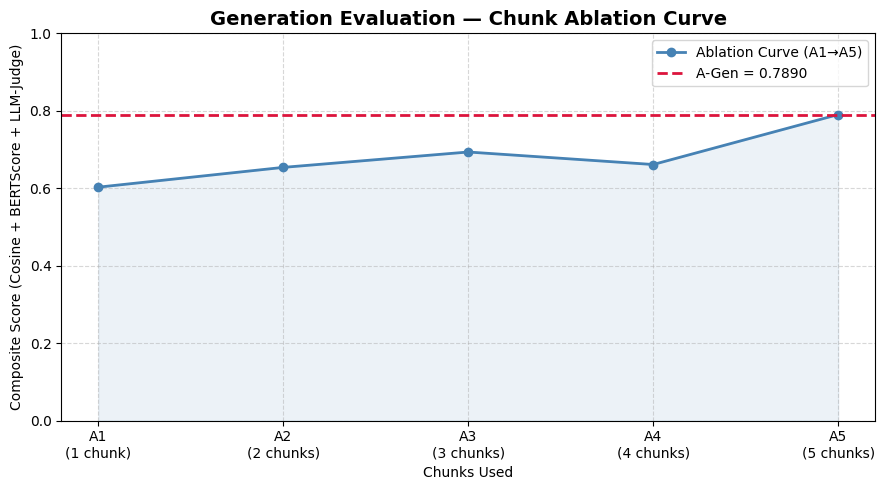


[✓] Plot saved to generation_eval_curve.png
[✓] Full results saved to generation_eval_results.json


In [ ]:
# ============================================================
# GENERATION EVALUATION - CHUNK ABLATION FRAMEWORK
# ============================================================

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from bert_score import score as bert_score
from sentence_transformers import SentenceTransformer, util
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
import chromadb

# ── CONFIG ───────────────────────────────────────────────────
GROQ_API_KEY = "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"
EVAL_LLM_MODEL = "llama-3.3-70b-versatile"   # One fixed LLM for all ablations
EMBED_MODEL_NAME = "all-MiniLM-L6-v2"
CHROMA_PATH = "chroma_db"
DATASET_PATH = "dataset.json"
CHUNKS_DB_PATH = "output/chunks_database.json"

# ── LOAD DEPENDENCIES ────────────────────────────────────────
embed_model = SentenceTransformer(EMBED_MODEL_NAME)
client = chromadb.PersistentClient(path=CHROMA_PATH)
collection = client.get_collection("pdf_chunks")

with open(DATASET_PATH, "r", encoding="utf-8") as f:
    dataset = json.load(f)

with open(CHUNKS_DB_PATH, "r", encoding="utf-8") as f:
    chunks_database = json.load(f)

llm = ChatGroq(
    model=EVAL_LLM_MODEL,
    api_key=GROQ_API_KEY,
    temperature=0.0,
    max_tokens=700
)

# ── HELPER: Generate answer from chunks ──────────────────────
def generate_answer(query, chunks):
    context = "\n\n".join([f"Chunk {i+1}: {c}" for i, c in enumerate(chunks)])
    prompt = f"""Answer the question using ONLY the provided context. Be concise.

Question: {query}

Context:
{context}

Answer:"""
    response = llm.invoke([HumanMessage(content=prompt)])
    return response.content.strip()

# ── HELPER: LLM-as-Judge ─────────────────────────────────────
def llm_judge(query, actual_answer, generated_answer):
    prompt = f"""Score the generated answer from 0 to 10 based on:
- Correctness: Is it factually correct compared to the actual answer?
- Faithfulness: Is it grounded in facts, no hallucinations?

Question: {query}
Actual Answer: {actual_answer}
Generated Answer: {generated_answer}

Return ONLY a single integer score between 0 and 10. Nothing else."""
    response = llm.invoke([HumanMessage(content=prompt)])
    try:
        return float(response.content.strip())
    except:
        return 0.0

# ── HELPER: Score one answer vs actual ───────────────────────
def score_answer(query, actual_answer, generated_answer):
    # 1. Cosine Similarity
    emb_actual = embed_model.encode(actual_answer, convert_to_tensor=True)
    emb_gen    = embed_model.encode(generated_answer, convert_to_tensor=True)
    cosine = float(util.cos_sim(emb_actual, emb_gen)[0][0])

    # 2. BERTScore (F1)
    P, R, F1 = bert_score([generated_answer], [actual_answer], lang="en", verbose=False)
    bert = float(F1[0])

    # 3. LLM-as-Judge
    judge = llm_judge(query, actual_answer, generated_answer) / 10.0  # normalize 0-1

    # Composite score (equal weights — adjust if needed)
    composite = (cosine + bert + judge) / 3.0

    return {
        "cosine":    round(cosine, 4),
        "bertscore": round(bert, 4),
        "llm_judge": round(judge, 4),
        "composite": round(composite, 4)
    }

# ── HELPER: Retrieve top-N chunks for a query ────────────────
def retrieve_chunks(query, n=5):
    q_emb = embed_model.encode(query, convert_to_numpy=True).tolist()
    results = collection.query(query_embeddings=[q_emb], n_results=n)
    return results["documents"][0]  # list of chunk texts

# ── MAIN EVALUATION LOOP ─────────────────────────────────────
evaluation_results = {}

# Evaluate only first 10 samples (remove slice for full eval)
sample_items = list(dataset.items())[:10]

for chunk_id, qa_pair in sample_items:
    query        = qa_pair["question"]
    actual_answer = qa_pair["answer"]

    print(f"\n{'='*60}")
    print(f"Q: {query[:80]}...")

    # ── Step 1: Retrieve top 5 chunks ────────────────────────
    top5_chunks = retrieve_chunks(query, n=5)

    # ── Step 2: Chunk Ablation — 5 answers with 1 fixed LLM ─
    ablation_answers = {}
    ablation_scores  = {}

    for k in range(1, 6):   # k = 1,2,3,4,5
        chunks_used = top5_chunks[:k]
        answer_k    = generate_answer(query, chunks_used)
        scores_k    = score_answer(query, actual_answer, answer_k)
        ablation_answers[f"A{k}"] = answer_k
        ablation_scores[f"A{k}"]  = scores_k
        print(f"  A{k} (chunks=1~{k}) → composite: {scores_k['composite']:.4f}")

    # ── Step 3: Your RAG Pipeline Answer (full pipeline) ─────
    # Replace this with your actual RAG pipeline call if different
    a_gen    = generate_answer(query, top5_chunks)
    a_gen_scores = score_answer(query, actual_answer, a_gen)
    print(f"  A-Gen              → composite: {a_gen_scores['composite']:.4f}")

    # ── Step 4: Diagnosis ─────────────────────────────────────
    # Ground truth chunk present in top5?
    gt_chunk_text = chunks_database.get(chunk_id, None)
    gt_in_top5 = any(gt_chunk_text in c for c in top5_chunks) if gt_chunk_text else None

    evaluation_results[chunk_id] = {
        "query":          query,
        "ablation_scores": ablation_scores,
        "a_gen_scores":   a_gen_scores,
        "gt_in_top5":     gt_in_top5
    }

# ── AGGREGATE RESULTS ─────────────────────────────────────────
print(f"\n\n{'='*60}")
print("AGGREGATED RESULTS")
print(f"{'='*60}")

avg_ablation = {f"A{k}": [] for k in range(1, 6)}
avg_gen = []

for qid, res in evaluation_results.items():
    for k in range(1, 6):
        avg_ablation[f"A{k}"].append(res["ablation_scores"][f"A{k}"]["composite"])
    avg_gen.append(res["a_gen_scores"]["composite"])

ablation_means = {k: round(np.mean(v), 4) for k, v in avg_ablation.items()}
gen_mean = round(np.mean(avg_gen), 4)

for k, v in ablation_means.items():
    print(f"  {k} avg composite score: {v}")
print(f"  A-Gen avg composite score: {gen_mean}")

# ── DIAGNOSIS SUMMARY ──────────────────────────────────────────
gt_missing = sum(1 for r in evaluation_results.values() if r["gt_in_top5"] == False)
gt_present = sum(1 for r in evaluation_results.values() if r["gt_in_top5"] == True)
print(f"\n  Ground truth chunk in top5:     {gt_present} / {len(evaluation_results)}")
print(f"  Ground truth chunk NOT in top5: {gt_missing} / {len(evaluation_results)}")
if gt_missing > 0:
    print("  → RETRIEVAL problem detected")

if gen_mean < ablation_means["A5"]:
    print("  → GENERATION problem: A-Gen scores below even single-chunk answer")
elif gen_mean >= ablation_means["A1"]:
    print("  → Pipeline performing well — matches or exceeds full-context answer")
else:
    print("  → Pipeline is reasonable but has room for improvement")

# ── PLOT THE ABLATION CURVE ────────────────────────────────────
x_labels = ["A1\n(1 chunk)", "A2\n(2 chunks)", "A3\n(3 chunks)", "A4\n(4 chunks)", "A5\n(5 chunks)"]
y_ablation = [ablation_means[f"A{k}"] for k in range(1, 6)]

plt.figure(figsize=(9, 5))
plt.plot(x_labels, y_ablation, marker="o", linewidth=2, color="steelblue", label="Ablation Curve (A1→A5)")
plt.axhline(y=gen_mean, color="crimson", linestyle="--", linewidth=2, label=f"A-Gen = {gen_mean:.4f}")
plt.fill_between(x_labels, y_ablation, alpha=0.1, color="steelblue")
plt.title("Generation Evaluation — Chunk Ablation Curve", fontsize=14, fontweight="bold")
plt.xlabel("Chunks Used")
plt.ylabel("Composite Score (Cosine + BERTScore + LLM-Judge)")
plt.legend()
plt.ylim(0, 1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("generation_eval_curve.png", dpi=150)
plt.show()
print("\n[✓] Plot saved to generation_eval_curve.png")

# ── SAVE RESULTS ──────────────────────────────────────────────
with open("generation_eval_results.json", "w", encoding="utf-8") as f:
    json.dump(evaluation_results, f, indent=4, ensure_ascii=False)
print("[✓] Full results saved to generation_eval_results.json")